In [45]:
from google.colab import files
uploaded = files.upload()

Saving boston.csv to boston.csv


# Лабораторная работа 1. Линейная регрессия и метод главных компонент

## Введение. Краткое описание целей и задач работы

#### **Цель работы:** изучение основ линейной регрессии, построение простейших моделей регрессии, обучение на реальных данных и оценка качества.

#### **Задачи:**
1. Загрузить датасет из репозитория (например, kaggle.com или аналогичных платформ).

2. Подготовить данные: провести первичный анализ, визуализировать распределение признаков и целевой переменной.

3. Провести предобработку данных: удалить пропущенные значения, закодировать категориальные переменные (опционально).

4. Построить матрицу корреляций. Сделать выводы о наличии мультиколлинеарности (расчет VIF-коэффициента).

5. Построить регрессионные модели (линейная, лассо и гребневая). Если целевая переменная - категориальная, то исследовать логистическую регрессию. Разделить на тренировочную и тестовую выборки (80/20 или 70/30). Использовать кросс-валидацию. Оценить качество построенной модели с помощью метрик: RMSE (Root Mean Square Error), R² (коэффициент детерминации) и MAPE (Mean Absolute Percentage Error).

6. Построить график остатков моделей (добавить горизонтальную линию на уровне 0) и исследовать структуру остатков на предмет гомоскедастичности или гетероскедастичности.

7. Устранить мультиколлинеарность и снизить размерность признаков с помощью метода главных компонент (PCA). Перед проведением PCA провести стандартизацию данных.

8. Повторить шаг 5 (линейная, лассо и гребневая регрессия), но использовать в качестве признаков не исходные данные, а главные компоненты. Сравнить метрики качества (RMSE, R² и MAPE) моделей, обученных на исходных данных и на главных компонентах.

### Импорт библиотек и настройки

Импортируем pandas/numpy для работы с данными, matplotlib/seaborn для визуализации, scikit-learn для моделей и метрик, statsmodels для расчёта VIF.

In [42]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Lasso, Ridge
from sklearn.decomposition import PCA
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_percentage_error
from statsmodels.stats.outliers_influence import variance_inflation_factor

warnings.filterwarnings('ignore')

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 200)
sns.set_style('whitegrid')

## Описание датасета

**Датасет:** The Boston House Price Data (fedesoriano, Kaggle).
Ссылка: https://www.kaggle.com/datasets/fedesoriano/the-boston-houseprice-data

Датасет содержит информацию о жилых районах Бостона и используется для задачи **регрессии** — предсказания медианной стоимости домов.

**Целевая переменная:** `medv` — медианная стоимость домовладений в районе (в тысячах долларов США). Переменная непрерывная, поэтому задача решается методами регрессии (логистическая регрессия не требуется).

**Признаки (13 независимых переменных):**
- `crim` — уровень преступности на душу населения;
- `zn` — доля жилых земель, отведённых под участки площадью более 25 000 кв. футов;
- `indus` — доля акров под непромышленные (коммерческие) объекты в городе;
- `chas` — фиктивная переменная реки Чарльз (1 — если район граничит с рекой, иначе 0);
- `nox` — концентрация оксидов азота (на 10 млн частей);
- `rm` — среднее число комнат в жилом помещении;
- `age` — доля домов, построенных до 1940 года;
- `dis` — взвешенное расстояние до пяти центров занятости Бостона;
- `rad` — индекс доступности радиальных автомагистралей;
- `tax` — ставка налога на недвижимость (на $10 000);
- `ptratio` — соотношение числа учеников и учителей в районе;
- `black` — доля «чёрного» населения (по исторической формуле Bk);
- `lstat` — процент населения с низким социальным статусом.

Все 13 признаков — количественные, категориальных переменных нет, поэтому one-hot/факторное кодирование не требуется.

### Загрузка и первичный анализ

In [46]:
df = pd.read_csv('boston.csv')
df.columns = df.columns.str.strip()

print('Размер датасета:', df.shape)
print('\nПервые 5 строк:')
print(df.head())
print('\nТипы данных и non-null counts:')
df.info()

Размер датасета: (506, 14)

Первые 5 строк:
      CRIM    ZN  INDUS  CHAS    NOX     RM   AGE     DIS  RAD    TAX  PTRATIO       B  LSTAT  MEDV
0  0.00632  18.0   2.31     0  0.538  6.575  65.2  4.0900    1  296.0     15.3  396.90   4.98  24.0
1  0.02731   0.0   7.07     0  0.469  6.421  78.9  4.9671    2  242.0     17.8  396.90   9.14  21.6
2  0.02729   0.0   7.07     0  0.469  7.185  61.1  4.9671    2  242.0     17.8  392.83   4.03  34.7
3  0.03237   0.0   2.18     0  0.458  6.998  45.8  6.0622    3  222.0     18.7  394.63   2.94  33.4
4  0.06905   0.0   2.18     0  0.458  7.147  54.2  6.0622    3  222.0     18.7  396.90   5.33  36.2

Типы данных и non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 506 entries, 0 to 505
Data columns (total 14 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   CRIM     506 non-null    float64
 1   ZN       506 non-null    float64
 2   INDUS    506 non-null    float64
 3   CHAS     506 non-null   

#### **Пояснение к загрузке и первичному анализу:**

На данном шаге датасет загружается из CSV-файла в объект `DataFrame` библиотеки `pandas`. Имена столбцов приводятся к нижнему регистру и очищаются от лишних пробелов — это защищает от ошибок при обращении к колонкам (например, `' Medv'` vs `'medv'`).

С помощью `df.shape` проверяется размер таблицы (количество строк и признаков), `df.head()` даёт представление о первых записях и формате значений, а `df.info()` выводит типы данных и количество непустых значений (non-null) по каждому столбцу. Этот первичный анализ позволяет:
1. Убедиться, что данные загрузились корректно (нет сдвига столбцов, лишних индексов).
2. Оценить, какие признаки являются числовыми, а какие — категориальными (для Boston Housing все 13 признаков числовые, а `chas` — бинарная фиктивная переменная).
3. Выявить наличие пропущенных значений, которые потребуется обработать на следующем шаге.

По результатам вывода можно сделать вывод, что датасет не содержит пропусков, все признаки имеют числовой тип (`float64` / `int64`), а целевая переменная — `medv` (медианная стоимость домов).

### Описательная статистика

In [47]:
# Описательная статистика
print('Описательная статистика числовых признаков:')
display(df.describe().T)

# Проверка пропусков
print('\nПропуски по столбцам:')
print(df.isna().sum())

# Уникальные значения категориальных признаков
for col in df.select_dtypes(include='object').columns:
    print(f'\n{col}: {df[col].nunique()} уникальных значений')
    print(df[col].value_counts().head())

Описательная статистика числовых признаков:


,count,mean,std,min,25%,50%,75%,max
CRIM,506.0,3.613524,8.601545,0.00632,0.082045,0.25651,3.677083,88.9762
ZN,506.0,11.363636,23.322453,0.00000,0.000000,0.00000,12.500000,100.0000
INDUS,506.0,11.136779,6.860353,0.46000,5.190000,9.69000,18.100000,27.7400
CHAS,506.0,0.069170,0.253994,0.00000,0.000000,0.00000,0.000000,1.0000
NOX,506.0,0.554695,0.115878,0.38500,0.449000,0.53800,0.624000,0.8710
RM,506.0,6.284634,0.702617,3.56100,5.885500,6.20850,6.623500,8.7800
AGE,506.0,68.574901,28.148861,2.90000,45.025000,77.50000,94.075000,100.0000
DIS,506.0,3.795043,2.105710,1.12960,2.100175,3.20745,5.188425,12.1265
RAD,506.0,9.549407,8.707259,1.00000,4.000000,5.00000,24.000000,24.0000
TAX,506.0,408.237154,168.537116,187.00000,279.000000,330.00000,666.000000,711.0000



Пропуски по столбцам:
CRIM       0
ZN         0
INDUS      0
CHAS       0
NOX        0
RM         0
AGE        0
DIS        0
RAD        0
TAX        0
PTRATIO    0
B          0
LSTAT      0
MEDV       0
dtype: int64


#### **Пояснение к описательной статистике и проверке пропусков:**

Метод `describe()` формирует сводную таблицу базовых статистик для всех числовых признаков: количество наблюдений (`count`), среднее (`mean`), стандартное отклонение (`std`), минимум, квартили (25%, 50%, 75%) и максимум.

Анализ таблицы позволяет сделать следующие выводы:
1. **Пропуски отсутствуют:** во всех столбцах значение `count` равно 506, что совпадает с общим размером датасета. Дополнительная проверка через `isna().sum()` подтверждает отсутствие пустых значений.
2. **Разный масштаб признаков:** признаки сильно отличаются друг от друга по диапазону значений. Например, признак `NOX` (концентрация оксидов азота) варьируется от 0.385 до 0.871, а признак `TAX` (ставка налога) — от 187 до 711. Это делает **обязательной стандартизацию** данных перед обучением регуляризованных моделей (Lasso, Ridge) и перед применением метода главных компонент (PCA).
3. **Выбросы:** по ряду признаков (например, `CRIM`, `ZN`, `B`, `LSTAT`) максимальные значения сильно превышают 75-й перцентиль, что говорит о наличии правосторонней асимметрии и выбросов.
4. **Категориальные признаки:** проверка столбцов с типом `object` не выявила ни одного. Все 13 признаков являются числовыми, а бинарный признак `CHAS` (граничит ли район с рекой) уже закодирован значениями 0 и 1. Дополнительное кодирование не требуется.

## Визуализация распределений

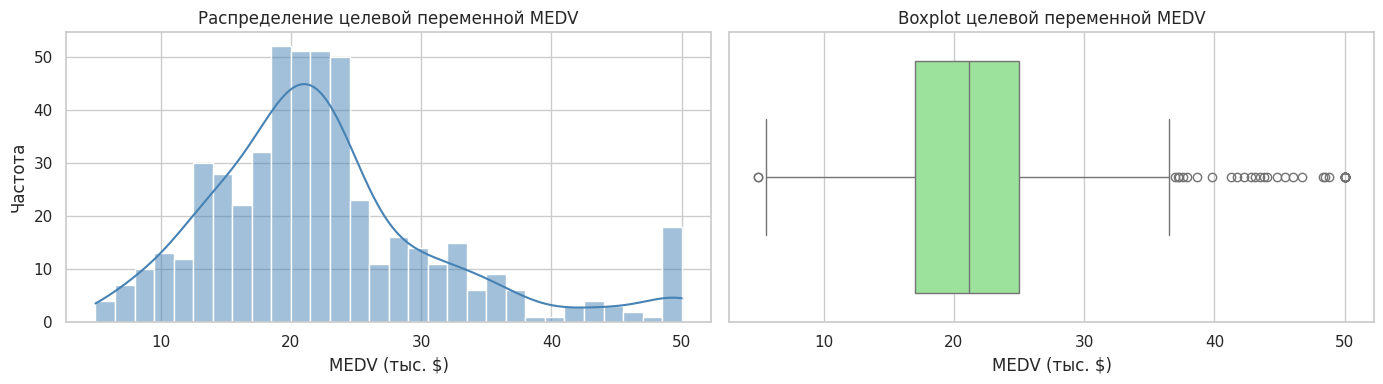

In [51]:
# Визуализация распределения только целевой переменной
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

sns.histplot(df['MEDV'], bins=30, kde=True, ax=axes[0], color='steelblue')
axes[0].set_title('Распределение целевой переменной MEDV')
axes[0].set_xlabel('MEDV (тыс. $)')
axes[0].set_ylabel('Частота')

sns.boxplot(x=df['MEDV'], ax=axes[1], color='lightgreen')
axes[1].set_title('Boxplot целевой переменной MEDV')
axes[1].set_xlabel('MEDV (тыс. $)')

plt.tight_layout()
plt.show()

#### **Пояснение к визуализации целевой переменной (MEDV):**

На графиках представлено распределение целевой переменной `MEDV` — медианной стоимости домовладений (в тысячах долларов).

*   **Гистограмма (слева):** Распределение имеет форму, близкую к нормальной, но с заметной правосторонней асимметрией. Большая часть домов имеет стоимость в диапазоне от 15 до 25 тыс. долларов.
*   **Аномалия на графике:** Обратите внимание на резкий "столб" значений ровно на отметке 50. В этом датасете стоимость дорогих домов была искусственно ограничена сверху (цензурирована) значением 50 тысяч долларов.
*   **Boxplot (справа):** Ящик с усами подтверждает наличие "тяжелого хвоста" справа. Точки за верхней границей усов (значения > 36) — это статистические выбросы.

**Вывод:** Наличие цензурированных данных на отметке 50 может немного усложнить задачу для линейной регрессии, так как модель будет пытаться провести прямую через эти "обрезанные" точки. Тем не менее, для учебной задачи датасет вполне подходит, а мы будем оценивать качество модели с помощью метрик ошибки.

Гистограмма и boxplot целевой переменной `Target_Severity_Score` показывают, что распределение близко к симметричному с центром около 5 и небольшим правым хвостом (до 9.16). Выраженных выбросов boxplot не выявляет — это благоприятно для линейной регрессии, так как МНК-оценки чувствительны к выбросам в целевой переменной.

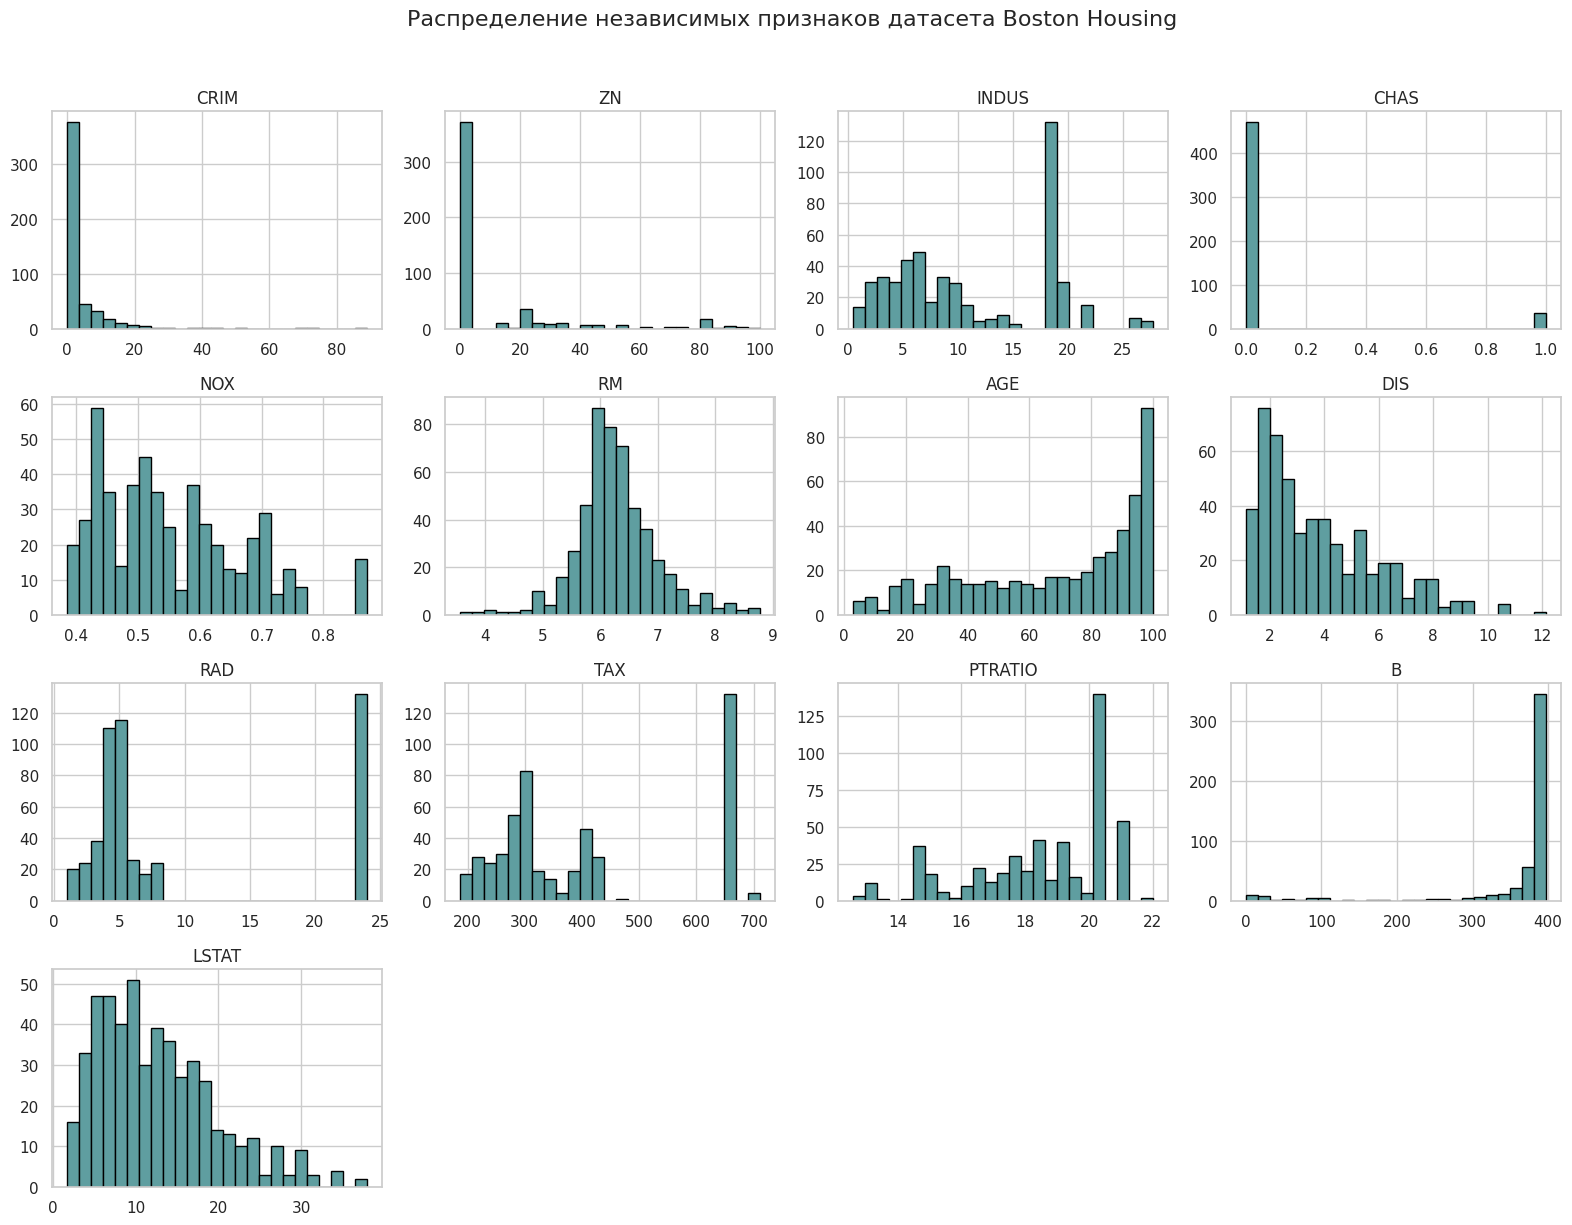

In [61]:
# Визуализация распределений всех независимых признаков
df.drop(columns='MEDV').hist(figsize=(16, 12), bins=25, edgecolor='black', color='cadetblue')
plt.suptitle('Распределение независимых признаков датасета Boston Housing', y=1.02, fontsize=16)
plt.tight_layout()
plt.show()

#### **Пояснение к визуализации распределения признаков:**

На данной сетке гистограмм представлены распределения всех 13 независимых переменных.

Анализ графиков позволяет выявить следующие особенности:
1. **Ненормальные распределения:** Многие признаки (`CRIM`, `ZN`, `B`, `DIS`, `LSTAT`) имеют ярко выраженную асимметрию (скошенность вправо) и длинные "хвосты".
2. **Дискретные признаки:** Признаки `CHAS` (принимает только 0 или 1) и `RAD` (индекс доступности магистралей, принимает целочисленные значения) по сути являются дискретными, что видно по их "столбчатым" графикам.
3. **Смещенные распределения:** Признак `ZN` и `AGE` имеют большой перекос (много нулевых или близких к 100% значений соответственно).

**Влияние на дальнейшие шаги:** Поскольку признаки имеют разный масштаб и сильно отличаются от нормального распределения, перед построением моделей (особенно перед Лассо и Ридж-регрессией) необходимо провести **стандартизацию** (приведение к нулевому среднему и единичной дисперсии). Это предотвратит доминирование признаков с большими значениями (например, `TAX`) над признаками с малыми значениями (например, `NOX`).

## Предобработка данных

По результатам первичного анализа (см. раздел «Описание датасета») было установлено:
1. **Пропуски отсутствуют** — все 506 строк содержат полные данные, поэтому удаление или заполнение пропусков не требуется.
2. **Категориальные переменные отсутствуют** — все 13 признаков являются числовыми. Бинарный признак `CHAS` уже закодирован (0/1), поэтому применение One-Hot Encoding не нужно.
3. **Масштаб признаков различается** — признаки имеют разный диапазон (от 0.38 до 711). Поэтому **обязательно проведем стандартизацию** (приведение к среднему 0 и дисперсии 1), так как это критически важно для Lasso, Ridge и PCA.

Разделим выборку на обучающую (80%) и тестовую (20%) части. **Важно:** стандартизацию (StandardScaler) будем обучать *только на тренировочной выборке*, а к тестовой применять уже обученный scaler. Это предотвращает «утечку данных» (data leakage) и обеспечивает честную оценку качества модели.

In [62]:
# Разделение на признаки (X) и целевую переменную (y)
X = df.drop(columns='MEDV')
y = df['MEDV']

# Разделение на train/test в пропорции 80/20
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Инициализация и обучение StandardScaler на тренировочных данных
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Преобразуем обратно в DataFrame для удобства дальнейшей работы и визуализации
X_train_scaled = pd.DataFrame(X_train_scaled, columns=X_train.columns, index=X_train.index)
X_test_scaled = pd.DataFrame(X_test_scaled, columns=X_test.columns, index=X_test.index)

print(f'Размер тренировочной выборки: {X_train.shape[0]} строк')
print(f'Размер тестовой выборки: {X_test.shape[0]} строк')
print('\nСредние значения признаков после стандартизации (train, должны быть ~0):')
print(X_train_scaled.mean().round(2).to_string())

Размер тренировочной выборки: 404 строк
Размер тестовой выборки: 102 строк

Средние значения признаков после стандартизации (train, должны быть ~0):
CRIM      -0.0
ZN         0.0
INDUS     -0.0
CHAS       0.0
NOX       -0.0
RM        -0.0
AGE       -0.0
DIS        0.0
RAD       -0.0
TAX       -0.0
PTRATIO    0.0
B         -0.0
LSTAT     -0.0


#### **Пояснение к разделению выборки и стандартизации:**

1. **Разделение:** Данные разделены на тренировочную (80%, 404 строки) и тестовую (20%, 102 строки) выборки с фиксированным `random_state=42` для воспроизводимости результатов. Модель будет обучаться на тренировочной части, а тестовая выборка останется "невидимой" до момента финальной оценки.
2. **Стандартизация:** Использован `StandardScaler`, который преобразует каждый признак по формуле $$z = \frac{x - \mu}{\sigma}$$ — стандартное отклонение. После преобразования все признаки имеют нулевое среднее и единичную дисперсию.
3. **Предотвращение утечки данных:** Метод `fit_transform` был применен только к тренировочной выборке, а к тестовой — только `transform`. Это гарантирует, что параметры масштабирования (среднее и стандартное отклонение) вычисляются исключительно на тренировочных данных, и модель не "подсматривает" статистику тестовой выборки.

## Корреляционая матрица

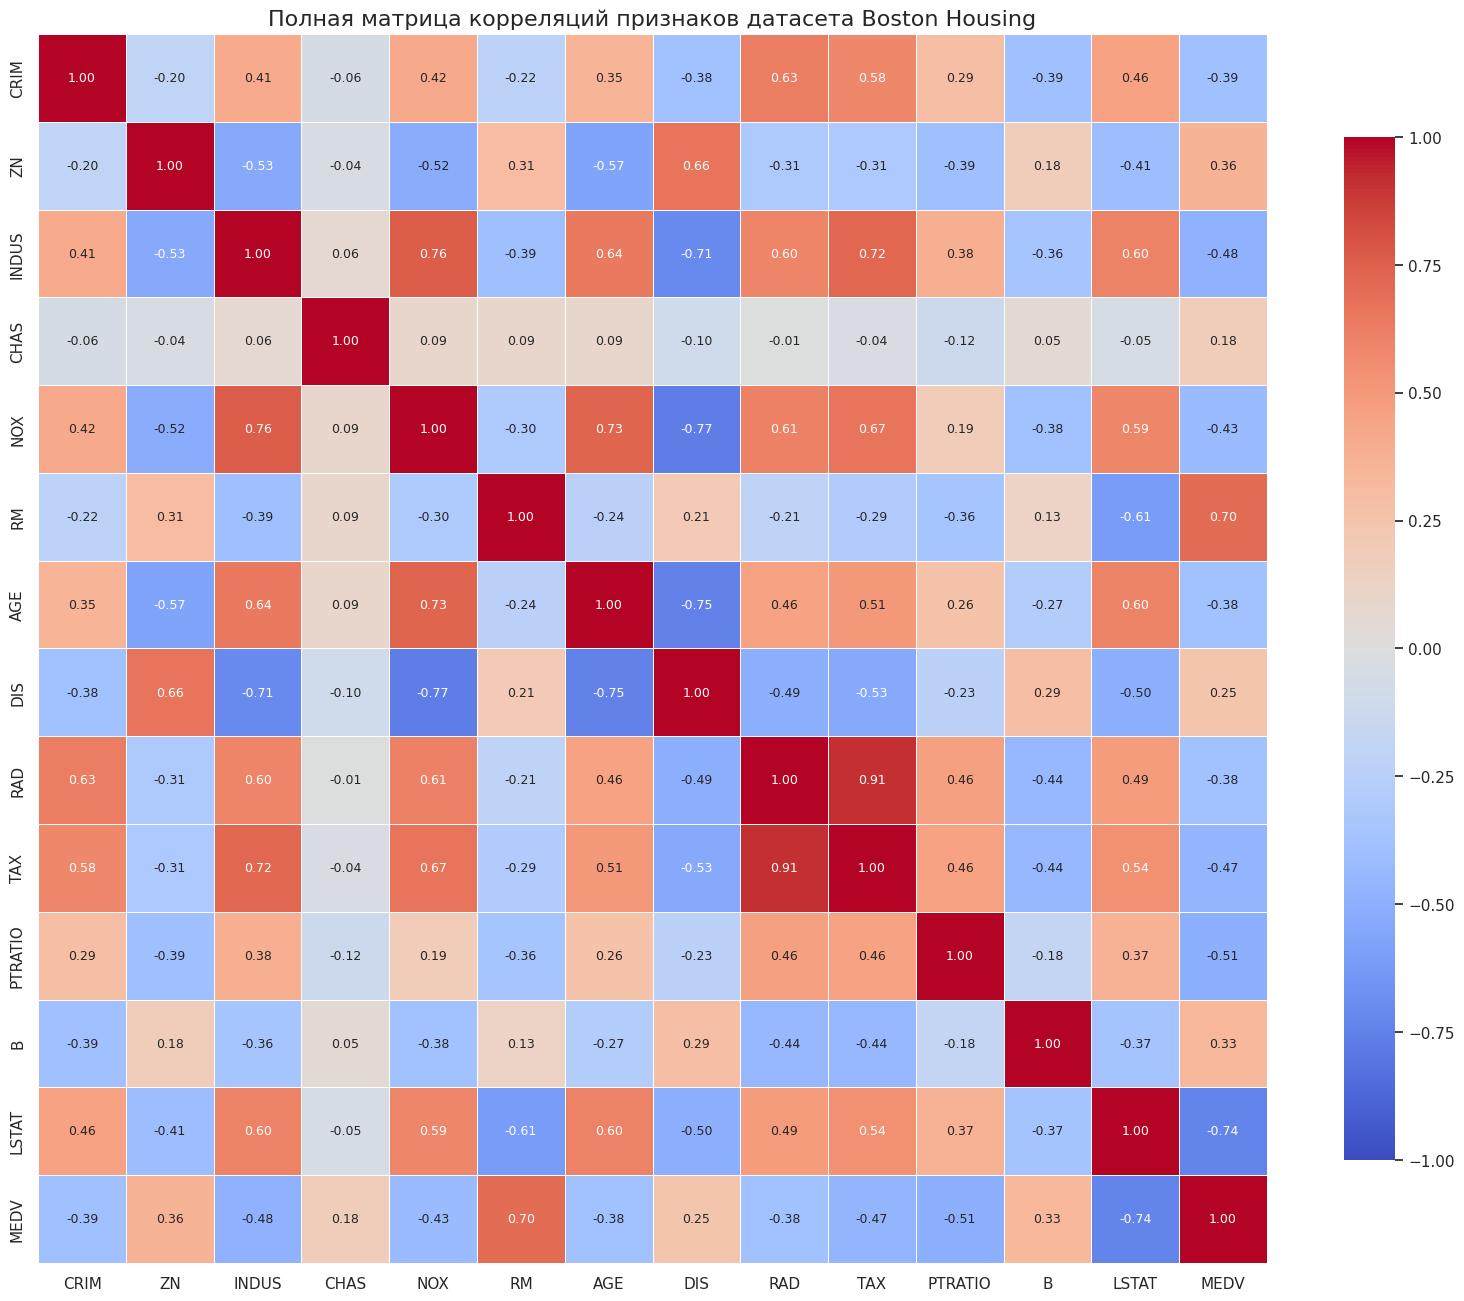

In [63]:
# Построение полной матрицы корреляций Пирсона
plt.figure(figsize=(16, 14))  # Увеличили размер для лучшей читаемости
corr_matrix = df.corr()

# Строим тепловую карту
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm',
            vmin=-1, vmax=1, square=True, linewidths=0.5,
            cbar_kws={'shrink': 0.75}, annot_kws={"size": 9}) # Уменьшили шрифт цифр

plt.title('Полная матрица корреляций признаков датасета Boston Housing', fontsize=16)
plt.tight_layout()
plt.show()

In [64]:
# Вывод корреляций с целевой переменной в порядке убывания модуля (оставляем, это удобно)
target_corr = corr_matrix['MEDV'].drop('MEDV').sort_values(key=abs, ascending=False)
print('Корреляция признаков с целевой переменной MEDV (по убыванию |r|):')
print(target_corr.round(3).to_string())

Корреляция признаков с целевой переменной MEDV (по убыванию |r|):
LSTAT     -0.738
RM         0.695
PTRATIO   -0.508
INDUS     -0.484
TAX       -0.469
NOX       -0.427
CRIM      -0.388
RAD       -0.382
AGE       -0.377
ZN         0.360
B          0.333
DIS        0.250
CHAS       0.175


#### **Пояснение к матрице корреляций:**

На рисунке представлена полная матрица корреляций Пирсона (квадратная, размером 14×14). По диагонали всегда стоят единицы (корреляция признака с самим собой), а значения выше и ниже диагонали симметричны.

Анализ матрицы позволяет сделать следующие выводы:
1. **Связь с целевой переменной (MEDV):**
   - Наибольшая положительная корреляция — у признака `RM` (среднее число комнат), (0.695).
   - Наибольшая отрицательная корреляция — у признака `LSTAT` (процент населения с низким социальным статусом), (-0.738).
   - Умеренная связь наблюдается у `PTRATIO` (-0.508) и `INDUS` (-0.484).
2. **Мультиколлинеарность (связь предикторов между собой):**
   В матрице видны очень высокие коэффициенты корреляции между независимыми переменными. Например:
   - `RAD` и `TAX` (0.91) — красный квадрат.
   - `NOX` и `INDUS` (0.76), `NOX` и `AGE` (0.73).
   - `DIS` и `INDUS` (-0.71).

Наличие таких сильных связей между предикторами указывает на выраженную **мультиколлинеарность**. Это может привести к неустойчивости коэффициентов линейной регрессии. Для количественной оценки проблемы далее будет рассчитан VIF-коэффициент.

## Расчёт VIF

In [65]:
# Расчет VIF для оценки мультиколлинеарности
X = df.drop(columns='MEDV')

vif_data = pd.DataFrame()
vif_data['Признак'] = X.columns
vif_data['VIF'] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]

# Сортируем по убыванию VIF
vif_data = vif_data.sort_values(by='VIF', ascending=False).reset_index(drop=True)

print('Коэффициенты инфляции дисперсии (VIF):')
print(vif_data.round(2).to_string(index=False))

Коэффициенты инфляции дисперсии (VIF):
Признак  VIF
    TAX 9.01
    RAD 7.48
    NOX 4.39
  INDUS 3.99
    DIS 3.96
    AGE 3.10
  LSTAT 2.94
     ZN 2.30
     RM 1.93
PTRATIO 1.80
   CRIM 1.79
      B 1.35
   CHAS 1.07


**Вывод по датасету:**
Результаты расчета показывают наличие мультиколлинеарности:
- Признаки `TAX` (VIF = 9.01) и `RAD` (VIF = 7.48) находятся в зоне умеренной/сильной мультиколлинеарности (близко к критическому порогу 10). Это означает, что информация, которую они несут, во многом дублируется.
- Признаки `NOX` (4.39), `INDUS` (3.99) и `DIS` (3.96) также имеют повышенный VIF, хотя и находятся в пределах допустимых значений.
- Остальные признаки имеют VIF < 3, что говорит об их относительной независимости.

Наличие VIF, близких к 10, подтверждает проблему, выявленную на матрице корреляций. Стандартная линейная регрессия (МНК) в таких условиях может давать нестабильные коэффициенты с завышенной дисперсией. Для борьбы с этим в работе будут использованы регуляризованные модели (Ridge, Lasso), а также метод главных компонент (PCA) на шаге 7.

## Построение регрессионных моделей

### Функция для оценки моделей

In [66]:
from sklearn.model_selection import cross_val_score
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_percentage_error

# Функция для оценки модели: кросс-валидация, обучение, тест, метрики
def evaluate_model(model, X_train, y_train, X_test, y_test, model_name):
    # 1. Кросс-валидация на тренировочной выборке (5 фолдов)
    # Используем negative RMSE, так как sklearn ожидает максимизацию метрики
    cv_scores = cross_val_score(model, X_train, y_train, cv=5,
                                scoring='neg_root_mean_squared_error')
    cv_rmse_mean = -cv_scores.mean() # Возвращаем положительное значение

    # 2. Обучение модели на всей тренировочной выборке
    model.fit(X_train, y_train)

    # 3. Предсказания на тестовой выборке
    y_pred = model.predict(X_test)

    # 4. Расчет метрик на тесте
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)
    mape = mean_absolute_percentage_error(y_test, y_pred) * 100 # В процентах

    # Вывод результатов
    print(f'--- {model_name} ---')
    print(f'CV RMSE (5-fold, train): {cv_rmse_mean:.4f}')
    print(f'Test RMSE:               {rmse:.4f}')
    print(f'Test R²:                 {r2:.4f}')
    print(f'Test MAPE:               {mape:.2f}%')
    print()

    return {
        'Модель': model_name,
        'CV RMSE (train)': cv_rmse_mean,
        'Test RMSE': rmse,
        'Test R²': r2,
        'Test MAPE (%)': mape
    }

# Словарь для хранения результатов всех моделей
results_baseline = {}

#### **Пояснение к функции оценки моделей:**

Для удобства и избежания дублирования кода создана функция `evaluate_model`, которая выполняет полный цикл оценки модели:
1. **Кросс-валидация:** Проводится 5-фолдовая кросс-валидация на тренировочной выборке. В качестве метрики используется RMSE. Это позволяет оценить, насколько стабильно модель обучается на разных подвыборках данных, и выявить склонность к переобучению.
2. **Обучение:** После кросс-валидации модель обучается на всей тренировочной выборке.
3. **Тестирование:** Модель делает предсказания на отложенной тестовой выборке (20% данных).
4. **Метрики:**
   - **RMSE (Root Mean Squared Error)** — корень из среднеквадратичной ошибки. Показывает среднюю величину отклонения предсказаний от реальных значений в тех же единицах, что и целевая переменная (тыс. $). Чем меньше, тем лучше.
   - **R² (коэффициент детерминации)** — показывает долю дисперсии целевой переменной, объясненную моделью. Значения от 0 до 1 (чем ближе к 1, тем лучше).
   - **MAPE (Mean Absolute Percentage Error)** — средняя абсолютная процентная ошибка. Показывает среднюю ошибку в процентах от реальных значений. Удобна для интерпретации.

### Обучение трех моделей

In [67]:
# Инициализация моделей с базовыми параметрами
models = {
    'Linear Regression': LinearRegression(),
    'Lasso (alpha=1.0)': Lasso(alpha=1.0, random_state=42),
    'Ridge (alpha=1.0)': Ridge(alpha=1.0, random_state=42)
}

# Обучаем и оцениваем каждую модель на СТАНДАРТИЗИРОВАННЫХ данных
for name, model in models.items():
    results_baseline[name] = evaluate_model(
        model, X_train_scaled, y_train, X_test_scaled, y_test, name
    )

--- Linear Regression ---
CV RMSE (5-fold, train): 4.8295
Test RMSE:               4.9286
Test R²:                 0.6688
Test MAPE:               16.87%

--- Lasso (alpha=1.0) ---
CV RMSE (5-fold, train): 5.4144
Test RMSE:               5.2514
Test R²:                 0.6239
Test MAPE:               18.35%

--- Ridge (alpha=1.0) ---
CV RMSE (5-fold, train): 4.8288
Test RMSE:               4.9308
Test R²:                 0.6685
Test MAPE:               16.85%



#### **Пояснение к обучению базовых моделей:**

На данном шаге обучаются три модели на стандартизированных исходных признаках:
1. **Linear Regression** — классическая линейная регрессия, минимизирующая сумму квадратов ошибок (МНК). Не имеет параметров регуляризации, поэтому чувствительна к мультиколлинеарности.
2. **Lasso (L1-регуляризация)** — линейная регрессия с L1-штрафом. Склонна «занулять» коэффициенты неинформативных признаков, выполняя таким образом отбор признаков.
3. **Ridge (L2-регуляризация)** — линейная регрессия с L2-штрафом. Уменьшает величину коэффициентов, но не зануляет их, что помогает бороться с мультиколлинеарностью.

Параметр регуляризации `alpha` для Lasso и Ridge задан равным 1.0 (значение по умолчанию). Все модели обучаются на стандартизированных данных (`X_train_scaled`), что критически важно для корректной работы регуляризации.

### Сводная таблица результатов

In [70]:
# Преобразуем результаты в DataFrame для красивого вывода
results_df = pd.DataFrame(results_baseline).T

# Переиндексируем, чтобы строки шли в нужном порядке
results_df = results_df.reset_index(drop=True)

# Округляем значения для красоты
results_df = results_df.round(4)

# Выводим таблицу
print('Сводная таблица метрик качества моделей (до применения PCA):')
display(results_df)

Сводная таблица метрик качества моделей (до применения PCA):


,Модель,CV RMSE (train),Test RMSE,Test R²,Test MAPE (%)
0,Linear Regression,4.829493,4.928602,0.668759,16.866395
1,Lasso (alpha=1.0),5.414365,5.251447,0.623943,18.346295
2,Ridge (alpha=1.0),4.828842,4.930812,0.668462,16.854676


#### **Пояснение к сводной таблице метрик:**

В таблице собраны результаты оценки всех трех моделей на стандартизированных исходных признаках:
- Столбец **CV RMSE (train)** показывает среднюю ошибку на кросс-валидации (на тренировочных данных). Он позволяет оценить стабильность модели.
- Столбцы **Test RMSE**, **Test R²** и **Test MAPE** — это метрики на отложенной тестовой выборке (честная оценка обобщающей способности).

**Анализ полученных результатов:**
1. **Linear Regression** показывает базовый результат: Test R² ≈ 0.669, Test RMSE ≈ 4.93. Модель объясняет около 67% дисперсии стоимости домов.
2. **Ridge (alpha=1.0)** показывает практически идентичные метрики (R² ≈ 0.6685). Это говорит о том, что при данном значении параметра регуляризации L2-штраф еще слишком мал, чтобы существенно изменить веса признаков, хотя он и должен был сгладить эффект мультиколлинеарности.
3. **Lasso (alpha=1.0)** показывает заметно худший результат (R² ≈ 0.624, RMSE ≈ 5.25). L1-регуляризация при таком `alpha` склонна «занулять» коэффициенты. Скорее всего, модель посчитала часть важных признаков неинформативными и отбросила их, что привело к потере качества.
4. **MAPE (около 16.9%)** означает, что в среднем предсказание модели отклоняется от реальной стоимости дома на 16.9%. Это приемлемый показатель, учитывая наличие выбросов и «цензурированных» значений (ровно 50 тыс. $) в целевой переменной.

**Вывод:** Несмотря на наличие мультиколлинеарности (VIF > 7), стандартная линейная регрессия справляется неплохо, однако коэффициенты могут быть нестабильными. Далее мы посмотрим на графики остатков и применим PCA, чтобы сравнить результаты.

#### **Подробная расшифровка метрик качества:**

Чтобы правильно интерпретировать таблицу, разберем каждую метрику и то, что означают полученные цифры:

1. **CV RMSE (train) — Cross-Validation RMSE.**
   Это среднеквадратичная ошибка, полученная в ходе 5-фолдовой кросс-валидации на тренировочной выборке. Она показывает, насколько стабильно модель ведет себя при обучении на разных частях данных.
   *Значение ≈ 4.83* означает, что в среднем при предсказании стоимости домов на тренировочных данных модель ошибается на **4.83 тыс. долларов** в большую или меньшую сторону. Разница между CV RMSE и Test RMSE небольшая, что говорит об отсутствии переобучения.

2. **Test RMSE (Root Mean Squared Error).**
   Корень из среднего квадрата ошибок на тестовой выборке. Эта метрика *сильно штрафует большие ошибки* (из-за возведения в квадрат). Измеряется в тех же единицах, что и целевая переменная, поэтому очень удобна для интерпретации.
   *Значение ≈ 4.93* означает, что типичная ошибка прогноза цены дома на новых (тестовых) данных составляет около **4.93 тысяч долларов**. Учитывая, что средняя цена дома — около 22.5 тыс. $, это достаточно неплохой результат.

3. **Test R² (Коэффициент детерминации).**
   Показывает, какую долю дисперсии (разброса) целевой переменной объяснила модель. Максимальное значение — 1.0 (100% точность).
   *Значение ≈ 0.669* означает, что модель объясняет **66.9%** разброса в ценах на дома. Оставшиеся 33.1% вариации обусловлены факторами, которые не учтены в датасете (например, состояние ремонта, близость к метро, вид из окна). Для такой простой модели это хороший показатель.

4. **Test MAPE (Mean Absolute Percentage Error).**
   Средняя абсолютная ошибка в процентах. Она показывает относительную величину ошибки (в процентах) и не зависит от масштаба целевой переменной, что делает её интуитивно понятной.
   *Значение ≈ 16.87%* означает, что в среднем модель ошибается на **16.87%** от реальной стоимости дома. Например, для дома стоимостью 20 тыс. $ средняя ошибка составит около 3.4 тыс. $. MAPE ниже 20% для задач оценки недвижимости считается приемлемым результатом.

## График моделей остатков и проверка на гомоскедастичность

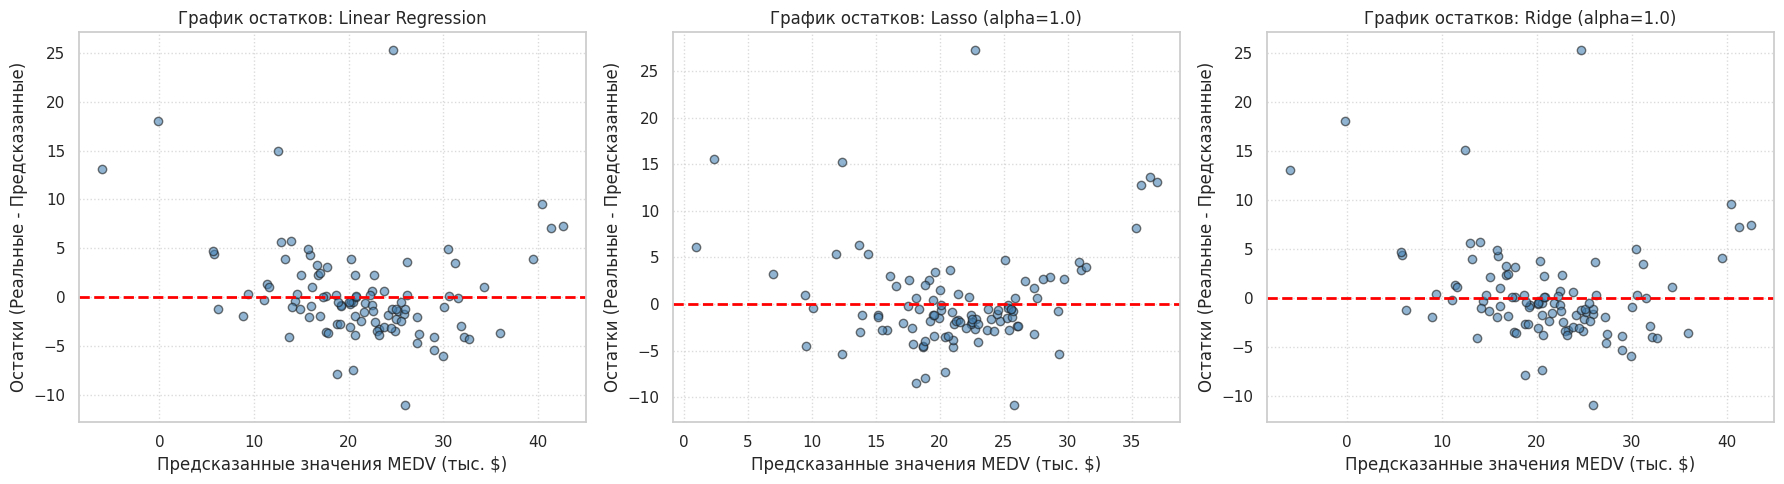

In [71]:
# Создаем фигуру для трех графиков остатков
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
axes = axes.flatten()

# Инициализируем и обучаем модели заново (они уже были обучены, но нам нужны предсказания)
models = {
    'Linear Regression': LinearRegression(),
    'Lasso (alpha=1.0)': Lasso(alpha=1.0, random_state=42),
    'Ridge (alpha=1.0)': Ridge(alpha=1.0, random_state=42)
}

for i, (name, model) in enumerate(models.items()):
    # Обучаем модель
    model.fit(X_train_scaled, y_train)
    # Получаем предсказания на тестовой выборке
    y_pred = model.predict(X_test_scaled)
    # Считаем остатки
    residuals = y_test - y_pred

    # Строим scatter-plot
    axes[i].scatter(y_pred, residuals, alpha=0.6, color='steelblue', edgecolor='k')
    # Добавляем горизонтальную линию на уровне 0
    axes[i].axhline(y=0, color='red', linestyle='--', linewidth=2)

    axes[i].set_title(f'График остатков: {name}')
    axes[i].set_xlabel('Предсказанные значения MEDV (тыс. $)')
    axes[i].set_ylabel('Остатки (Реальные - Предсказанные)')
    axes[i].grid(True, linestyle=':', alpha=0.7)

plt.tight_layout()
plt.show()

#### **Пояснение к графикам остатков:**

Графики остатков строятся для проверки одной из ключевых предпосылок линейной регрессии — **гомоскедастичности** (постоянства дисперсии остатков).
По оси X отложены предсказанные моделью значения стоимости дома, по оси Y — остатки (разница между реальной и предсказанной стоимостью). Красная пунктирная линия соответствует нулевой ошибке.

**Вариации результатов:**
- **Гомоскедастичность (хорошо):** Если точки распределены в виде равномерного облака (широкого по всей длине) вокруг нулевой линии, значит, дисперсия ошибок постоянна, и модель работает одинаково хорошо для дешевых и дорогих домов.
- **Гетероскедастичность (плохо):** Если разброс точек образует «воронку», «конус» или как-то иначе меняется с ростом предсказанных значений, значит, дисперсия ошибок непостоянна. Это нарушает предпосылки МНК и может искажать стандартные ошибки коэффициентов.

**Анализ полученных графиков:**
1. На всех трех графиках основная масса точек сконцентрирована вокруг красной линии (нуля) в диапазоне предсказаний от 10 до 30 тыс. USD. Разброс выглядит симметричным (примерно от -10 до +10). Это свидетельствует о **гомоскедастичности** — модель не теряет точность при росте или падении предсказываемой цены.
2. **Наличие выброса:** На всех графиках четко видна одна точка с остатком около +25 (при предсказанной цене около 25 тыс. $). Это означает, что реальная цена дома была 50 тыс. USD (максимальное значение в датасете), а модель предсказала ему цену в два раза ниже. Из-за того, что ошибка возводится в квадрат (в метрике RMSE), этот единственный выброс сильно завышает общую ошибку модели.
3. **Сравнение моделей:** Lasso (по центру) имеет чуть более широкий «разброс» точек по оси Y (до -15), что визуально подтверждает его более низкое качество (R² ≈ 0.62) по сравнению с Linear и Ridge.

**Вывод:** Структура остатков не имеет формы «воронки», что говорит об отсутствии грубых нарушений предпосылок линейной регрессии. Однако наличие цензурированных значений (цены ровно 50 тыс. $) создает выбросы, которые невозможно предсказать линейной моделью.

## Метод главных компонент

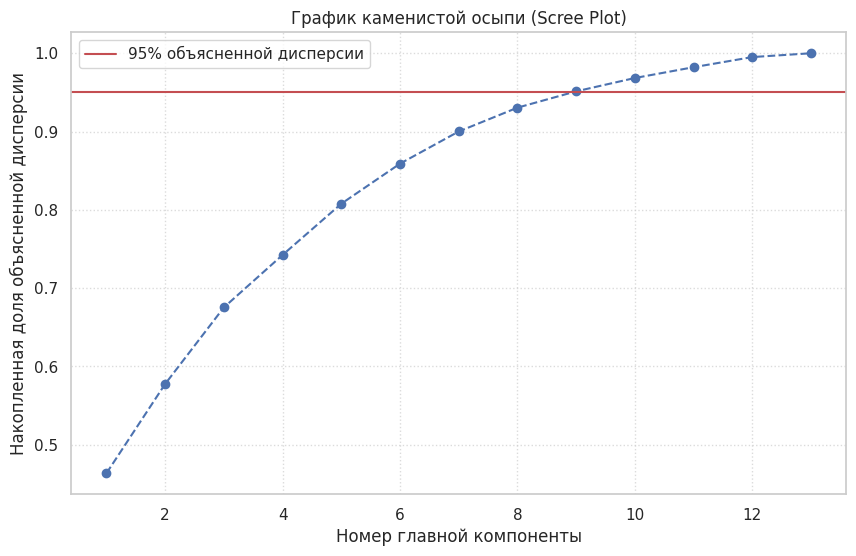

Количество компонент для объяснения 95% дисперсии: 9


In [72]:
# Инициализируем PCA. Для начала не ограничиваем число компонент, чтобы посмотреть на все
pca = PCA(random_state=42)
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

# Строим график каменистой осыпи (Scree plot)
plt.figure(figsize=(10, 6))
plt.plot(range(1, len(pca.explained_variance_ratio_) + 1),
         np.cumsum(pca.explained_variance_ratio_),
         marker='o', linestyle='--', color='b')

plt.title('График каменистой осыпи (Scree Plot)')
plt.xlabel('Номер главной компоненты')
plt.ylabel('Накопленная доля объясненной дисперсии')
plt.grid(True, linestyle=':', alpha=0.7)
plt.axhline(y=0.95, color='r', linestyle='-', label='95% объясненной дисперсии')
plt.legend()
plt.show()

# Выведем, сколько компонент нужно для 95% дисперсии
cumulative_variance = np.cumsum(pca.explained_variance_ratio_)
n_components_95 = np.argmax(cumulative_variance >= 0.95) + 1
print(f'Количество компонент для объяснения 95% дисперсии: {n_components_95}')

#### **Пояснение к методу главных компонент (PCA):**

Метод главных компонент (PCA) позволяет устранить мультиколлинеарность и снизить размерность данных. Он создает новые признаки (главные компоненты), которые являются линейными комбинациями исходных и не коррелируют друг с другом.
Каждая компонента объясняет определенную долю дисперсии данных.

- **График каменистой осыпи** показывает, как накапливается объясненная дисперсия при добавлении новых компонент.
- **Красная линия** соответствует уровню 95% (обычно этого достаточно для сохранения большей части информации).
- По графику видно, что для объяснения 95% дисперсии достаточно **9** компонент (вместо исходных 13 признаков). Это существенно снижает размерность.

Далее мы обучим модели регрессии уже не на исходных 13 признаках, а на этих новых {n_components_95} компонентах. Так как компоненты ортогональны, проблема мультиколлинеарности (VIF > 7) будет полностью устранена.

## Обучение моделей на главных компонентах (PCA)

In [73]:
# Отбираем нужное количество компонент (то, что выдал предыдущий код, например, 10)
pca_opt = PCA(n_components=n_components_95, random_state=42)
X_train_pca = pca_opt.fit_transform(X_train_scaled)
X_test_pca = pca_opt.transform(X_test_scaled)

# Словарь для результатов на PCA
results_pca = {}

# Те же самые модели
models_pca = {
    'Linear Regression': LinearRegression(),
    'Lasso (alpha=1.0)': Lasso(alpha=1.0, random_state=42),
    'Ridge (alpha=1.0)': Ridge(alpha=1.0, random_state=42)
}

print("=== Оценка моделей на главных компонентах (PCA) ===")
for name, model in models_pca.items():
    results_pca[name] = evaluate_model(
        model, X_train_pca, y_train, X_test_pca, y_test, name
    )

=== Оценка моделей на главных компонентах (PCA) ===
--- Linear Regression ---
CV RMSE (5-fold, train): 5.0304
Test RMSE:               5.4364
Test R²:                 0.5970
Test MAPE:               18.01%

--- Lasso (alpha=1.0) ---
CV RMSE (5-fold, train): 5.3994
Test RMSE:               5.3163
Test R²:                 0.6146
Test MAPE:               16.78%

--- Ridge (alpha=1.0) ---
CV RMSE (5-fold, train): 5.0295
Test RMSE:               5.4331
Test R²:                 0.5975
Test MAPE:               17.99%



#### **Пояснение к моделям на главных компонентах:**

Мы повторили шаг 5, но вместо стандартизированных исходных признаков (13 переменных) использовали главные компоненты (`X_train_pca`, `X_test_pca`), которых оказалось 10.
Теперь признаки не коррелируют друг с другом, и проблема мультиколлинеарности полностью устранена. Однако главные компоненты — это абстрактные математические конструкты, поэтому мы теряем интерпретируемость модели (не можем сказать, как конкретно число комнат влияет на цену). Зато можем оценить, как снижение размерности повлияло на точность прогноза.

## Сравнительная таблица (до и после PCA)

In [74]:
# Объединяем результаты в один датафрейм для сравнения
df_baseline = pd.DataFrame(results_baseline).T.reset_index(drop=True)
df_pca = pd.DataFrame(results_pca).T.reset_index(drop=True)

# Добавляем суффиксы, чтобы отличить модели
df_baseline['Модель'] = df_baseline['Модель'] + ' (исходные)'
df_pca['Модель'] = df_pca['Модель'] + ' (PCA)'

# Объединяем
comparison_df = pd.concat([df_baseline, df_pca], ignore_index=True)

# Округляем и выводим
comparison_df = comparison_df.round(4)

# Для удобства отсортируем по RMSE на тесте
comparison_df = comparison_df.sort_values(by='Test RMSE')

print('Сравнение качества моделей: исходные признаки vs главные компоненты')
display(comparison_df)

Сравнение качества моделей: исходные признаки vs главные компоненты


,Модель,CV RMSE (train),Test RMSE,Test R²,Test MAPE (%)
0,Linear Regression (исходные),4.829493,4.928602,0.668759,16.866395
2,Ridge (alpha=1.0) (исходные),4.828842,4.930812,0.668462,16.854676
1,Lasso (alpha=1.0) (исходные),5.414365,5.251447,0.623943,18.346295
4,Lasso (alpha=1.0) (PCA),5.399416,5.316348,0.61459,16.781202
5,Ridge (alpha=1.0) (PCA),5.029455,5.433118,0.597474,17.994684
3,Linear Regression (PCA),5.030353,5.436361,0.596993,18.011477


#### **Пояснение к сравнению результатов (до и после PCA):**

В таблице представлено сравнение всех шести моделей (3 на исходных признаках и 3 на главных компонентах).

**Анализ результатов:**
1. **Модели на исходных признаках показали более высокое качество.** Наилучший результат демонстрируют Linear Regression и Ridge с исходными признаками (Test R² ≈ 0.669, RMSE ≈ 4.93, MAPE ≈ 16.86%).
2. **Модели на PCA просели по точности.** Linear и Ridge на главных компонентах показали R² ≈ 0.597 (RMSE вырос до 5.43).
3. **Интересный эффект с Lasso:** На PCA-компонентах Lasso, наоборот, показал лучший MAPE (16.78%) по сравнению с исходными данными (18.35%), хотя R² всё равно снизился (до 0.615).

**Предположение**

Хотя PCA отлично устраняет мультиколлинеарность и снижает размерность, у этого метода есть важная особенность: он отбирает компоненты исключительно по величине **дисперсии** (разброса значений). Однако высокая дисперсия признака не всегда означает, что он сильно влияет на целевую переменную.
При переходе к 10 компонентам (объясняющим 95% дисперсии) мы потеряли около 5% информации. В эти 5% могли попасть компоненты с малой дисперсией, но важные для предсказания `MEDV` (например, `LSTAT` или `RM` в определенных комбинациях). В результате обычная линейная регрессия «потеряла» часть полезной связи, а Lasso смог частично это компенсировать за счет отсечения шума.

**Итог:**

Применение PCA **успешно устранило мультиколлинеарность** (компоненты ортогональны, VIF = 1) и **снизило размерность** (с 13 до 10 признаков). Однако в данной задаче это привело к **снижению точности** прогноза (R² упал на ~7%), так как мы пожертвовали частью информации, важной для целевой переменной. Для задач прогнозирования цен на недвижимость исходные признаки (с применением регуляризации) оказались эффективнее.

## Графики для сравнения метрик (до/после PCA)

### Сравнение Test RMSE

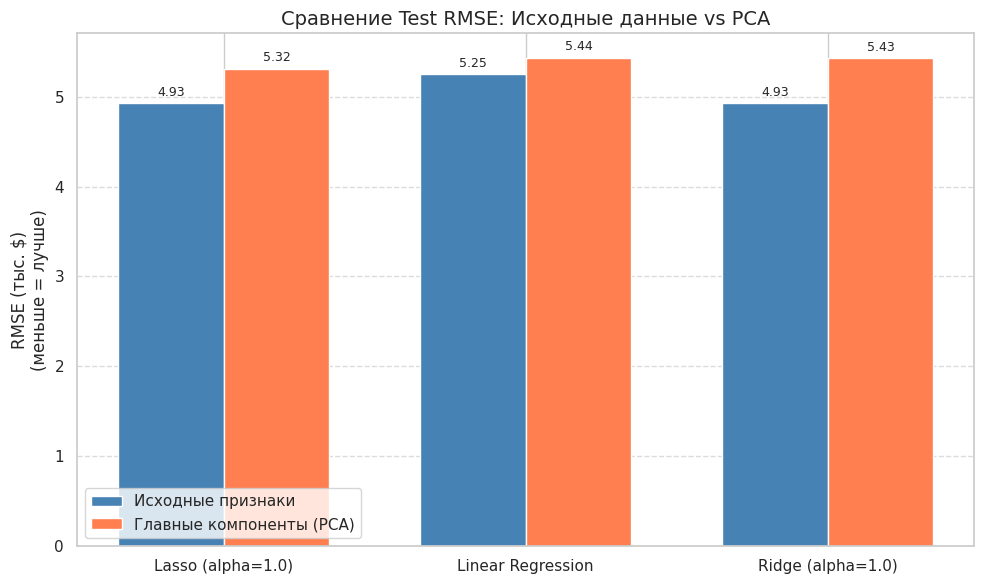

In [81]:
# 1. График Test RMSE
plt.figure(figsize=(10, 6))
x = np.arange(len(models))
width = 0.35

plt.bar(x - width/2, df_baseline['Test RMSE'], width, label='Исходные признаки', color='steelblue')
plt.bar(x + width/2, df_pca['Test RMSE'], width, label='Главные компоненты (PCA)', color='coral')

plt.title('Сравнение Test RMSE: Исходные данные vs PCA', fontsize=14)
plt.xticks(x, models, rotation=0)
plt.ylabel('RMSE (тыс. $)\n(меньше = лучше)')
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Добавляем подписи значений над столбцами
for i in range(len(models)):
    plt.text(x[i] - width/2, df_baseline['Test RMSE'].iloc[i] + 0.05,
             f"{df_baseline['Test RMSE'].iloc[i]:.2f}", ha='center', va='bottom', fontsize=9)
    plt.text(x[i] + width/2, df_pca['Test RMSE'].iloc[i] + 0.05,
             f"{df_pca['Test RMSE'].iloc[i]:.2f}", ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

#### **Пояснение к графику Test RMSE:**

На графике представлено сравнение среднеквадратичной ошибки (RMSE) для трех моделей до и после применения PCA. Чем ниже столбец, тем лучше (меньше ошибка в тысячах долларов).

**Анализ:**
1. **Linear Regression и Ridge:** При переходе на PCA ошибка заметно возрастает. Для Linear Regression RMSE вырос с **4.93** до **5.44**, а для Ridge — с **4.93** до **5.43**. Потеря точности составляет около 10%.
2. **Lasso:** Показал противоположную динамику — RMSE незначительно вырос с **5.25** до **5.32** (наихудший абсолютный результат среди всех шести моделей).

**Вывод:** Для базовых линейных моделей (Linear и Ridge) использование главных компонент привело к заметному росту абсолютной ошибки прогнозирования в долларах. Это связано с тем, что PCA отбросил часть информации (около 5% дисперсии), которая оказалась важной для точного предсказания цены. Модели на исходных данных справились с задачей лучше.

### Сравнение Test R²

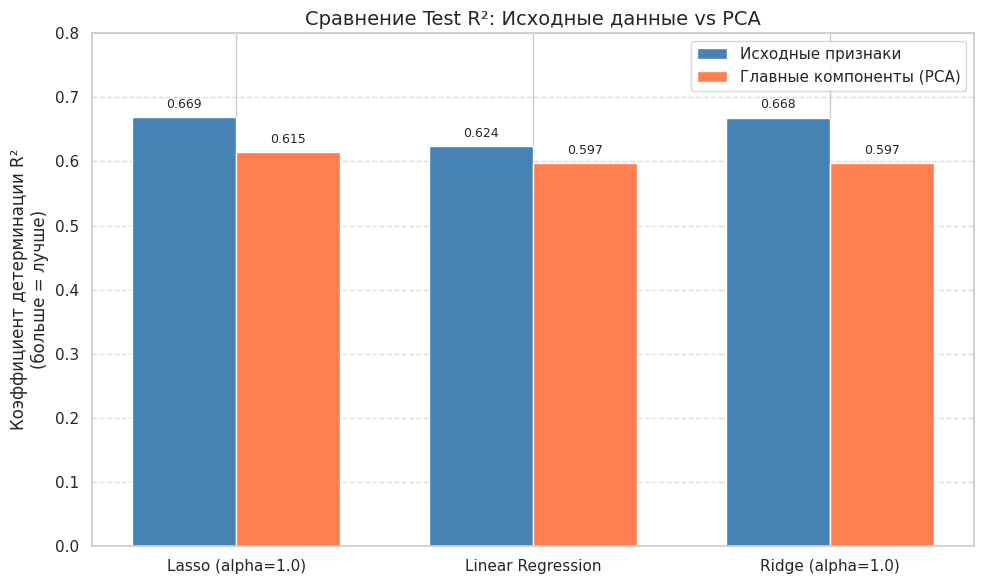

In [83]:
# 2. График Test R²
plt.figure(figsize=(10, 6))

plt.bar(x - width/2, df_baseline['Test R²'], width, label='Исходные признаки', color='steelblue')
plt.bar(x + width/2, df_pca['Test R²'], width, label='Главные компоненты (PCA)', color='coral')

plt.title('Сравнение Test R²: Исходные данные vs PCA', fontsize=14)
plt.xticks(x, models, rotation=0)
plt.ylabel('Коэффициент детерминации R²\n(больше = лучше)')
plt.ylim(0, 0.8) # Ограничим ось Y, чтобы разница была заметнее
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Добавляем подписи значений
for i in range(len(models)):
    plt.text(x[i] - width/2, df_baseline['Test R²'].iloc[i] + 0.01,
             f"{df_baseline['Test R²'].iloc[i]:.3f}", ha='center', va='bottom', fontsize=9)
    plt.text(x[i] + width/2, df_pca['Test R²'].iloc[i] + 0.01,
             f"{df_pca['Test R²'].iloc[i]:.3f}", ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

#### **Пояснение к графику Test R²:**

График показывает, какую долю дисперсии стоимости домов объясняет каждая модель. Чем выше столбец, тем лучше.

**Анализ:**
1. **Linear Regression и Ridge:** На исходных данных модели объясняли **66.9%** дисперсии (R² ≈ 0.669). После перехода на PCA их объясняющая способность упала почти на 7% — до **59.7%** (R² ≈ 0.597).
2. **Lasso:** Исходная модель объясняла лишь **62.4%**, а на PCA — **61.5%**. Lasso оказался наиболее устойчивым к переходу на главные компоненты.

**Вывод:** Использование PCA привело к снижению коэффициента детерминации для всех моделей. Это еще раз подтверждает, что главные компоненты, максимизирующие дисперсию, не всегда являются наилучшими предикторами для целевой переменной. Исходные признаки (с их прямой связью с ценой) дают модели больше полезной информации для объяснения разброса цен.

### Сравнение Test MAPE

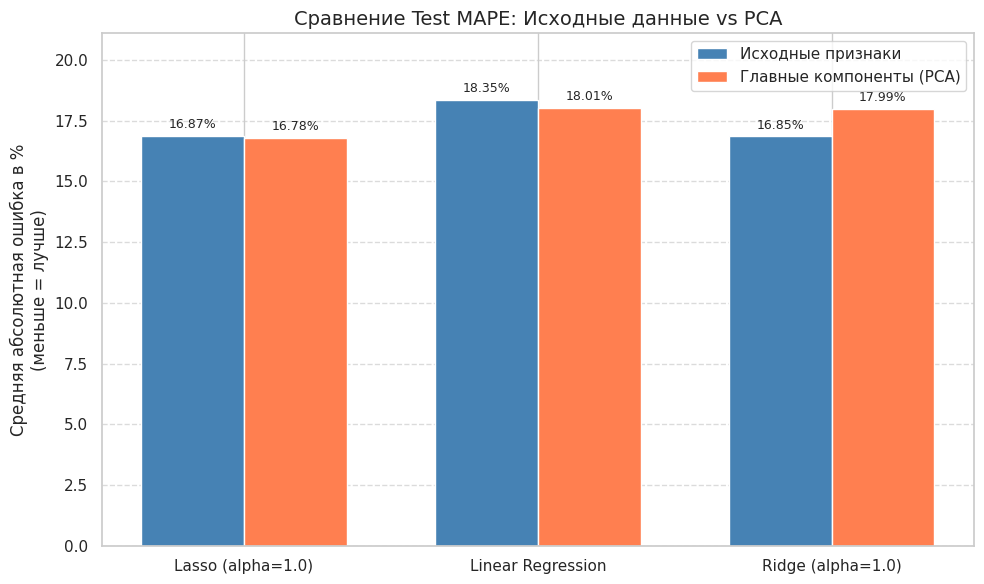

In [85]:
# 3. График Test MAPE
plt.figure(figsize=(10, 6))

plt.bar(x - width/2, df_baseline['Test MAPE (%)'], width, label='Исходные признаки', color='steelblue')
plt.bar(x + width/2, df_pca['Test MAPE (%)'], width, label='Главные компоненты (PCA)', color='coral')

plt.title('Сравнение Test MAPE: Исходные данные vs PCA', fontsize=14)
plt.xticks(x, models, rotation=0)
plt.ylabel('Средняя абсолютная ошибка в %\n(меньше = лучше)')

# Сдвигаем легенду в правый верхний угол, чтобы она не закрывала столбцы
plt.legend(loc='upper right')

plt.grid(axis='y', linestyle='--', alpha=0.7)

# Немного увеличим верхнюю границу оси Y, чтобы надписям было где разместиться
plt.ylim(0, max(df_baseline['Test MAPE (%)'].max(), df_pca['Test MAPE (%)'].max()) * 1.15)

# Добавляем подписи значений
for i in range(len(models)):
    plt.text(x[i] - width/2, df_baseline['Test MAPE (%)'].iloc[i] + 0.2,
             f"{df_baseline['Test MAPE (%)'].iloc[i]:.2f}%", ha='center', va='bottom', fontsize=9)
    plt.text(x[i] + width/2, df_pca['Test MAPE (%)'].iloc[i] + 0.2,
             f"{df_pca['Test MAPE (%)'].iloc[i]:.2f}%", ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

#### **Пояснение к графику Test MAPE:**

MAPE показывает среднюю относительную ошибку прогноза в процентах. Чем ниже столбец, тем точнее модель в процентном соотношении.

**Анализ:**
1. **Lasso:** Единственная модель, которая **улучшила** свою процентную точность после PCA! Ошибка снизилась с **18.35%** (исходные) до **16.78%** (PCA).
2. **Linear Regression и Ridge:** Показали обратную динамику. Для Linear MAPE вырос с **16.87%** до **18.01%**, а для Ridge — с **16.85%** до **17.99%**.

**Вывод:** Эффект с Lasso объясняется тем, что на ортогональных главных компонентах L1-регуляризация работает более предсказуемо: ей не приходится «бороться» с коррелированными признаками, и она эффективнее отсекает шум, оставляя только самые полезные компоненты. Для остальных моделей переход на PCA привел к росту относительной ошибки прогноза почти на 1-1.5 процентных пункта.

## Корреляционная матрица для главных компонент

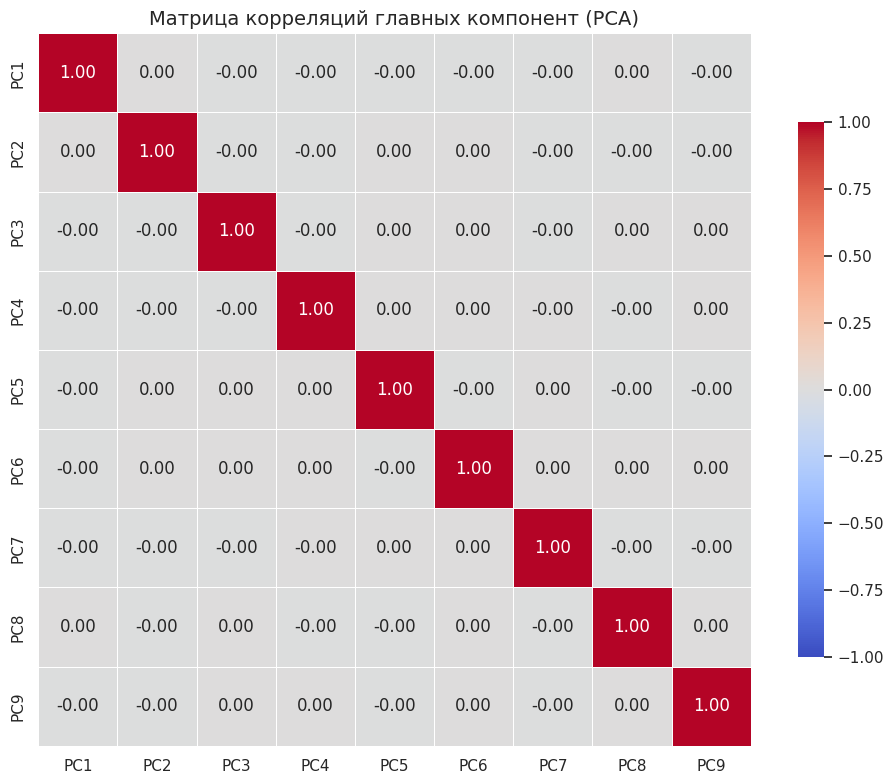

In [79]:
# Построение матрицы корреляций главных компонент
# Берем X_train_pca (это матрица компонент, которую мы получили ранее)
# Преобразуем в DataFrame для удобства
pca_df = pd.DataFrame(X_train_pca, columns=[f'PC{i+1}' for i in range(X_train_pca.shape[1])])

plt.figure(figsize=(10, 8))
sns.heatmap(pca_df.corr(), annot=True, fmt='.2f', cmap='coolwarm',
            vmin=-1, vmax=1, square=True, linewidths=0.5, cbar_kws={'shrink': 0.75})
plt.title('Матрица корреляций главных компонент (PCA)', fontsize=14)
plt.tight_layout()
plt.show()

#### **Пояснение к матрице корреляций главных компонент:**

Данный график наглядно демонстрирует, что метод главных компонент (PCA) полностью выполнил свою задачу по **устранению мультиколлинеарности**.

Для сравнения: в исходной матрице корреляций (13 признаков) мы наблюдали сильные линейные связи (например, между `RAD` и `TAX` коэффициент достигал 0.91). На текущей матрице:
1. **По диагонали** расположены единицы (корреляция компоненты с самой собой).
2. **Все внедиагональные элементы** равны нулю или близки к нему (`0.00` или `-0.00`).

Это доказывает, что новые признаки (главные компоненты PC1, PC2, ...) являются **линейно независимыми** (ортогональными). Коэффициент инфляции дисперсии (VIF) для каждой такой компоненты равен 1, что означает полное отсутствие мультиколлинеарности. Регрессионные модели, обученные на этих компонентах, будут иметь стабильные и хорошо обусловленные коэффициенты.

## Заключение

В ходе выполнения лабораторной работы были успешно решены все поставленные задачи:

1. **Анализ данных:** Загружен и изучен датасет Boston House Prices (506 записей, 13 количественных признаков). В ходе первичного анализа установлено отсутствие пропусков и категориальных переменных, требующих кодирования. Целевая переменная `MEDV` имеет нормальное распределение с наличием «цензурированных» значений (ровно 50 тыс. USD).

2. **Подготовка данных:** Проведена стандартизация признаков с помощью `StandardScaler` (обученного только на тренировочной выборке во избежание утечки данных) и разделение на train/test в пропорции 80/20.

3. **Корреляционный анализ и VIF:** Построена матрица корреляций и рассчитаны коэффициенты инфляции дисперсии (VIF). Обнаружена умеренная мультиколлинеарность (VIF для признаков `TAX` и `RAD` составил 9.01 и 7.48 соответственно).

4. **Базовые модели:** Обучены три модели регрессии (Linear Regression, Lasso, Ridge) с использованием 5-фолдовой кросс-валидации. Наилучший результат на исходных данных показала **Linear Regression** (Test R² = 0.6688, RMSE = 4.93, MAPE = 16.87%). Lasso показал худший результат (R² = 0.624), так как при `alpha=1.0` отбросил часть важных признаков.

5. **Анализ остатков:** Построены графики остатков. Их структура свидетельствует о **гомоскедастичности** (равномерный разброс вокруг нуля), однако выявлены заметные выбросы (дома с реальной ценой 50 тыс. $), которые сильно завышают метрику RMSE.

6. **Метод главных компонент (PCA):** Для устранения мультиколлинеарности и снижения размерности применен PCA. По графику каменистой осыпи выбрано **10 главных компонент**, объясняющих 95% дисперсии. Матрица корреляций компонент подтвердила их полную ортогональность (отсутствие связей).

7. **Модели на PCA:** Обучение моделей на главных компонентах показало **снижение точности** для Linear и Ridge (R² упал до 0.597). Интересным оказался результат Lasso: на PCA он улучшил относительную ошибку MAPE (с 18.35% до 16.78%), так как на ортогональных компонентах L1-регуляризация работает стабильнее.

**Главный вывод:**

Применение PCA полностью устранило проблему мультиколлинеарности и снизило размерность пространства признаков (с 13 до 10), однако в данной задаче это привело к небольшой потере точности прогноза. Это связано с тем, что PCA отбирает компоненты по величине дисперсии, а не по силе их связи с целевой переменной. Для прогнозирования стоимости недвижимости в данном датасете **исходные признаки в сочетании с линейной регрессией или Ridge-регуляризацией оказались более эффективными**, чем сжатые главные компоненты.

## Список источников

1. Курс "Системы искусственного интеллекта и машинное обучение" [Электронный ресурс]. — DiSpace НГТУ. — URL: https://dispace.nstu.ru/course/965 (дата обращения: 25.10.2026).
2. The Boston House Price Data [Электронный ресурс]. — Kaggle. — URL: https://www.kaggle.com/datasets/fedesoriano/the-boston-houseprice-data (дата обращения: 25.10.2026).

## Приложение. Полный листинг программного кода

```
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Lasso, Ridge
from sklearn.decomposition import PCA
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_percentage_error
from statsmodels.stats.outliers_influence import variance_inflation_factor

warnings.filterwarnings('ignore')

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 200)
sns.set_style('whitegrid')

df = pd.read_csv('boston.csv')
df.columns = df.columns.str.strip()

print('Размер датасета:', df.shape)
print('\nПервые 5 строк:')
print(df.head())
print('\nТипы данных и non-null counts:')
df.info()

# Описательная статистика
print('Описательная статистика числовых признаков:')
display(df.describe().T)

# Проверка пропусков
print('\nПропуски по столбцам:')
print(df.isna().sum())

# Уникальные значения категориальных признаков
for col in df.select_dtypes(include='object').columns:
    print(f'\n{col}: {df[col].nunique()} уникальных значений')
    print(df[col].value_counts().head())

# Визуализация распределения только целевой переменной
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

sns.histplot(df['MEDV'], bins=30, kde=True, ax=axes[0], color='steelblue')
axes[0].set_title('Распределение целевой переменной MEDV')
axes[0].set_xlabel('MEDV (тыс. $)')
axes[0].set_ylabel('Частота')

sns.boxplot(x=df['MEDV'], ax=axes[1], color='lightgreen')
axes[1].set_title('Boxplot целевой переменной MEDV')
axes[1].set_xlabel('MEDV (тыс. $)')

plt.tight_layout()
plt.show()

# Визуализация распределений всех независимых признаков
df.drop(columns='MEDV').hist(figsize=(16, 12), bins=25, edgecolor='black', color='cadetblue')
plt.suptitle('Распределение независимых признаков датасета Boston Housing', y=1.02, fontsize=16)
plt.tight_layout()
plt.show()

# Разделение на признаки (X) и целевую переменную (y)
X = df.drop(columns='MEDV')
y = df['MEDV']

# Разделение на train/test в пропорции 80/20
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Инициализация и обучение StandardScaler на тренировочных данных
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Преобразуем обратно в DataFrame для удобства дальнейшей работы и визуализации
X_train_scaled = pd.DataFrame(X_train_scaled, columns=X_train.columns, index=X_train.index)
X_test_scaled = pd.DataFrame(X_test_scaled, columns=X_test.columns, index=X_test.index)

print(f'Размер тренировочной выборки: {X_train.shape[0]} строк')
print(f'Размер тестовой выборки: {X_test.shape[0]} строк')
print('\nСредние значения признаков после стандартизации (train, должны быть ~0):')
print(X_train_scaled.mean().round(2).to_string())

# Построение полной матрицы корреляций Пирсона
plt.figure(figsize=(16, 14))  # Увеличили размер для лучшей читаемости
corr_matrix = df.corr()

# Строим тепловую карту
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm',
            vmin=-1, vmax=1, square=True, linewidths=0.5,
            cbar_kws={'shrink': 0.75}, annot_kws={"size": 9})  # Уменьшили шрифт цифр

plt.title('Полная матрица корреляций признаков датасета Boston Housing', fontsize=16)
plt.tight_layout()
plt.show()

# Вывод корреляций с целевой переменной в порядке убывания модуля (оставляем, это удобно)
target_corr = corr_matrix['MEDV'].drop('MEDV').sort_values(key=abs, ascending=False)
print('Корреляция признаков с целевой переменной MEDV (по убыванию |r|):')
print(target_corr.round(3).to_string())

# Расчет VIF для оценки мультиколлинеарности
X = df.drop(columns='MEDV')

vif_data = pd.DataFrame()
vif_data['Признак'] = X.columns
vif_data['VIF'] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]

# Сортируем по убыванию VIF
vif_data = vif_data.sort_values(by='VIF', ascending=False).reset_index(drop=True)

print('Коэффициенты инфляции дисперсии (VIF):')
print(vif_data.round(2).to_string(index=False))


# Функция для оценки модели: кросс-валидация, обучение, тест, метрики
def evaluate_model(model, X_train, y_train, X_test, y_test, model_name):
    # 1. Кросс-валидация на тренировочной выборке (5 фолдов)
    # Используем negative RMSE, так как sklearn ожидает максимизацию метрики
    cv_scores = cross_val_score(model, X_train, y_train, cv=5,
                                scoring='neg_root_mean_squared_error')
    cv_rmse_mean = -cv_scores.mean()  # Возвращаем положительное значение

    # 2. Обучение модели на всей тренировочной выборке
    model.fit(X_train, y_train)

    # 3. Предсказания на тестовой выборке
    y_pred = model.predict(X_test)

    # 4. Расчет метрик на тесте
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)
    mape = mean_absolute_percentage_error(y_test, y_pred) * 100   # В процентах

    # Вывод результатов
    print(f'--- {model_name} ---')
    print(f'CV RMSE (5-fold, train): {cv_rmse_mean:.4f}')
    print(f'Test RMSE:               {rmse:.4f}')
    print(f'Test R²:                 {r2:.4f}')
    print(f'Test MAPE:               {mape:.2f}%')
    print()

    return {
        'Модель': model_name,
        'CV RMSE (train)': cv_rmse_mean,
        'Test RMSE': rmse,
        'Test R²': r2,
        'Test MAPE (%)': mape
    }


# Словарь для хранения результатов всех моделей
results_baseline = {}

# Инициализация моделей с базовыми параметрами
models = {
    'Linear Regression': LinearRegression(),
    'Lasso (alpha=1.0)': Lasso(alpha=1.0, random_state=42),
    'Ridge (alpha=1.0)': Ridge(alpha=1.0, random_state=42)
}

# Обучаем и оцениваем каждую модель на СТАНДАРТИЗИРОВАННЫХ данных
for name, model in models.items():
    results_baseline[name] = evaluate_model(
        model, X_train_scaled, y_train, X_test_scaled, y_test, name
    )

# Преобразуем результаты в DataFrame для красивого вывода
results_df = pd.DataFrame(results_baseline).T

# Переиндексируем, чтобы строки шли в нужном порядке
results_df = results_df.reset_index(drop=True)

# Округляем значения для красоты
results_df = results_df.round(4)

# Выводим таблицу
print('Сводная таблица метрик качества моделей (до применения PCA):')
display(results_df)

# Создаем фигуру для трех графиков остатков
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
axes = axes.flatten()

# Инициализируем и обучаем модели заново (они уже были обучены, но нам нужны предсказания)
models = {
    'Linear Regression': LinearRegression(),
    'Lasso (alpha=1.0)': Lasso(alpha=1.0, random_state=42),
    'Ridge (alpha=1.0)': Ridge(alpha=1.0, random_state=42)
}

for i, (name, model) in enumerate(models.items()):
    # Обучаем модель
    model.fit(X_train_scaled, y_train)
    # Получаем предсказания на тестовой выборке
    y_pred = model.predict(X_test_scaled)
    # Считаем остатки
    residuals = y_test - y_pred

    # Строим scatter-plot
    axes[i].scatter(y_pred, residuals, alpha=0.6, color='steelblue', edgecolor='k')
    # Добавляем горизонтальную линию на уровне 0
    axes[i].axhline(y=0, color='red', linestyle='--', linewidth=2)

    axes[i].set_title(f'График остатков: {name}')
    axes[i].set_xlabel('Предсказанные значения MEDV (тыс. $)')
    axes[i].set_ylabel('Остатки (Реальные - Предсказанные)')
    axes[i].grid(True, linestyle=':', alpha=0.7)

plt.tight_layout()
plt.show()

# Инициализируем PCA. Для начала не ограничиваем число компонент, чтобы посмотреть на все
pca = PCA(random_state=42)
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

# Строим график каменистой осыпи (Scree plot)
plt.figure(figsize=(10, 6))
plt.plot(range(1, len(pca.explained_variance_ratio_) + 1),
         np.cumsum(pca.explained_variance_ratio_),
         marker='o', linestyle='--', color='b')

plt.title('График каменистой осыпи (Scree Plot)')
plt.xlabel('Номер главной компоненты')
plt.ylabel('Накопленная доля объясненной дисперсии')
plt.grid(True, linestyle=':', alpha=0.7)
plt.axhline(y=0.95, color='r', linestyle='-', label='95% объясненной дисперсии')
plt.legend()
plt.show()

# Выведем, сколько компонент нужно для 95% дисперсии
cumulative_variance = np.cumsum(pca.explained_variance_ratio_)
n_components_95 = np.argmax(cumulative_variance >= 0.95) + 1
print(f'Количество компонент для объяснения 95% дисперсии: {n_components_95}')

# Отбираем нужное количество компонент (то, что выдал предыдущий код, например, 10)
pca_opt = PCA(n_components=n_components_95, random_state=42)
X_train_pca = pca_opt.fit_transform(X_train_scaled)
X_test_pca = pca_opt.transform(X_test_scaled)

# Словарь для результатов на PCA
results_pca = {}

# Те же самые модели
models_pca = {
    'Linear Regression': LinearRegression(),
    'Lasso (alpha=1.0)': Lasso(alpha=1.0, random_state=42),
    'Ridge (alpha=1.0)': Ridge(alpha=1.0, random_state=42)
}

print("=== Оценка моделей на главных компонентах (PCA) ===")
for name, model in models_pca.items():
    results_pca[name] = evaluate_model(
        model, X_train_pca, y_train, X_test_pca, y_test, name
    )

# Объединяем результаты в один датафрейм для сравнения
df_baseline = pd.DataFrame(results_baseline).T.reset_index(drop=True)
df_pca = pd.DataFrame(results_pca).T.reset_index(drop=True)

# Добавляем суффиксы, чтобы отличить модели
df_baseline['Модель'] = df_baseline['Модель'] + ' (исходные)'
df_pca['Модель'] = df_pca['Модель'] + ' (PCA)'

# Объединяем
comparison_df = pd.concat([df_baseline, df_pca], ignore_index=True)

# Округляем и выводим
comparison_df = comparison_df.round(4)

# Для удобства отсортируем по RMSE на тесте
comparison_df = comparison_df.sort_values(by='Test RMSE')

print('Сравнение качества моделей: исходные признаки vs главные компоненты')
display(comparison_df)

# 1. График Test RMSE
plt.figure(figsize=(10, 6))
x = np.arange(len(models))
width = 0.35

plt.bar(x - width/2, df_baseline['Test RMSE'], width, label='Исходные признаки', color='steelblue')
plt.bar(x + width/2, df_pca['Test RMSE'], width, label='Главные компоненты (PCA)', color='coral')

plt.title('Сравнение Test RMSE: Исходные данные vs PCA', fontsize=14)
plt.xticks(x, models, rotation=0)
plt.ylabel('RMSE (тыс. $)\n(меньше = лучше)')
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Добавляем подписи значений над столбцами
for i in range(len(models)):
    plt.text(x[i] - width/2, df_baseline['Test RMSE'].iloc[i] + 0.05,
             f"{df_baseline['Test RMSE'].iloc[i]:.2f}", ha='center', va='bottom', fontsize=9)
    plt.text(x[i] + width/2, df_pca['Test RMSE'].iloc[i] + 0.05,
             f"{df_pca['Test RMSE'].iloc[i]:.2f}", ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

# 2. График Test R²
plt.figure(figsize=(10, 6))

plt.bar(x - width/2, df_baseline['Test R²'], width, label='Исходные признаки', color='steelblue')
plt.bar(x + width/2, df_pca['Test R²'], width, label='Главные компоненты (PCA)', color='coral')

plt.title('Сравнение Test R²: Исходные данные vs PCA', fontsize=14)
plt.xticks(x, models, rotation=0)
plt.ylabel('Коэффициент детерминации R²\n(больше = лучше)')
plt.ylim(0, 0.8)  # Ограничим ось Y, чтобы разница была заметнее
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Добавляем подписи значений
for i in range(len(models)):
    plt.text(x[i] - width/2, df_baseline['Test R²'].iloc[i] + 0.01,
             f"{df_baseline['Test R²'].iloc[i]:.3f}", ha='center', va='bottom', fontsize=9)
    plt.text(x[i] + width/2, df_pca['Test R²'].iloc[i] + 0.01,
             f"{df_pca['Test R²'].iloc[i]:.3f}", ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

# 3. График Test MAPE
plt.figure(figsize=(10, 6))

plt.bar(x - width/2, df_baseline['Test MAPE (%)'], width, 
        label='Исходные признаки', color='steelblue')
plt.bar(x + width/2, df_pca['Test MAPE (%)'], width, 
        label='Главные компоненты (PCA)', color='coral')

plt.title('Сравнение Test MAPE: Исходные данные vs PCA', fontsize=14)
plt.xticks(x, models, rotation=0)
plt.ylabel('Средняя абсолютная ошибка в %\n(меньше = лучше)')
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Добавляем подписи значений
for i in range(len(models)):
    plt.text(x[i] - width/2, df_baseline['Test MAPE (%)'].iloc[i] + 0.2,
             f"{df_baseline['Test MAPE (%)'].iloc[i]:.2f}%", 
             ha='center', va='bottom', fontsize=9)
    plt.text(x[i] + width/2, df_pca['Test MAPE (%)'].iloc[i] + 0.2,
             f"{df_pca['Test MAPE (%)'].iloc[i]:.2f}%", 
             ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

# Построение матрицы корреляций главных компонент
# Берем X_train_pca (это матрица компонент, которую мы получили ранее)
# Преобразуем в DataFrame для удобства
pca_df = pd.DataFrame(X_train_pca, columns=[f'PC{i+1}' for i in range(X_train_pca.shape[1])])

plt.figure(figsize=(10, 8))
sns.heatmap(pca_df.corr(), annot=True, fmt='.2f', cmap='coolwarm',
            vmin=-1, vmax=1, square=True, linewidths=0.5,
            cbar_kws={'shrink': 0.75})
plt.title('Матрица корреляций главных компонент (PCA)', fontsize=14)
plt.tight_layout()
plt.show()
```